# Error analysis: ошибки и неуверенные предсказания

Анализ одной выбранной модели на **val**. Измените EXPERIMENT_ID и запустите сверху вниз. По умолчанию — лучший checkpoint ResNet101.

Полные вероятности читаются из `artifacts/predictions/<EXPERIMENT_ID>/val_probabilities.npz`. Если файла нет, выполняется один val-only inference из `best.pt` без TTA; probabilities сохраняются для следующих запусков. На CPU это может занять время. Ни обучение, ни test не используются; raw и experiments.csv не изменяются.

Для ансамблей, TTA и аудита специалистов используйте `06_tta_ensembles.ipynb`.


In [7]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src/error_analysis.py").is_file():
    raise RuntimeError("Откройте ноутбук из корня проекта или notebooks/")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.error_analysis import (
    validation_probabilities, probability_cases, plot_probability_cases,
    class_metrics, confusion_pairs, plot_confusion, show_errors, show_train_examples,
)

EXPERIMENT_ID = "resnet101_partial_domain_shift_stronger_001"
RAW_DIR = PROJECT_ROOT / "data/raw"
PROBABILITIES_PATH = None  # None: стандартный val_probabilities.npz этого запуска
DEVICE = "auto"  # auto / cpu / cuda
BATCH_SIZE = 16
NUM_WORKERS = 0  # удобно для Windows; на Kaggle можно увеличить
TOP_K = 5  # например, 3 или 5
UNCERTAIN_TOP_N = 30  # можно поставить 50
PAGE_SIZE = 6  # объектов на страницу, у каждого картинка + вероятности


In [8]:
probabilities, classes = validation_probabilities(
    PROJECT_ROOT, EXPERIMENT_ID, raw_dir=RAW_DIR,
    probabilities_path=PROBABILITIES_PATH, device=DEVICE,
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
)
scored = probabilities.table(include_scores=True)
PRIMARY = EXPERIMENT_ID
frame = scored.set_index("id").rename(columns={"label": PRIMARY})
print(f"{EXPERIMENT_ID}: {len(scored)} val изображений; "
      f"accuracy={scored.label.eq(scored.true_label).mean():.4%}; "
      f"ошибок={scored.label.ne(scored.true_label).sum()}")


Loaded validation probabilities: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\predictions\resnet101_partial_domain_shift_stronger_001\val_probabilities.npz
resnet101_partial_domain_shift_stronger_001: 699 val изображений; accuracy=96.9957%; ошибок=21


## Ошибки по классам

Recall, precision и пары ошибок показывают, какие классы пропускаем и куда ошибочно относим снимки.


,class_name,support,errors,false_positives,recall_pct,precision_pct,f1_pct
0,church,35,7,0,80.00,100.00,88.89
1,lake,35,4,2,88.57,93.94,91.18
2,basketball_court,35,2,0,94.29,100.00,97.06
3,palace,35,2,5,94.29,86.84,90.41
4,wetland,35,2,3,94.29,91.67,92.96
5,railway,35,1,0,97.14,100.00,98.55
6,railway_station,35,1,0,97.14,100.00,98.55
7,sea_ice,35,1,0,97.14,100.00,98.55
8,terrace,35,1,2,97.14,94.44,95.77
9,baseball_diamond,35,0,0,100.00,100.00,100.00


,true_class,predicted_class,count
0,church,palace,4
1,church,commercial_area,3
2,lake,wetland,2
3,palace,commercial_area,2
4,wetland,lake,2
5,basketball_court,tennis_court,1
6,basketball_court,terrace,1
7,lake,runway,1
8,lake,snowberg,1
9,railway,terrace,1


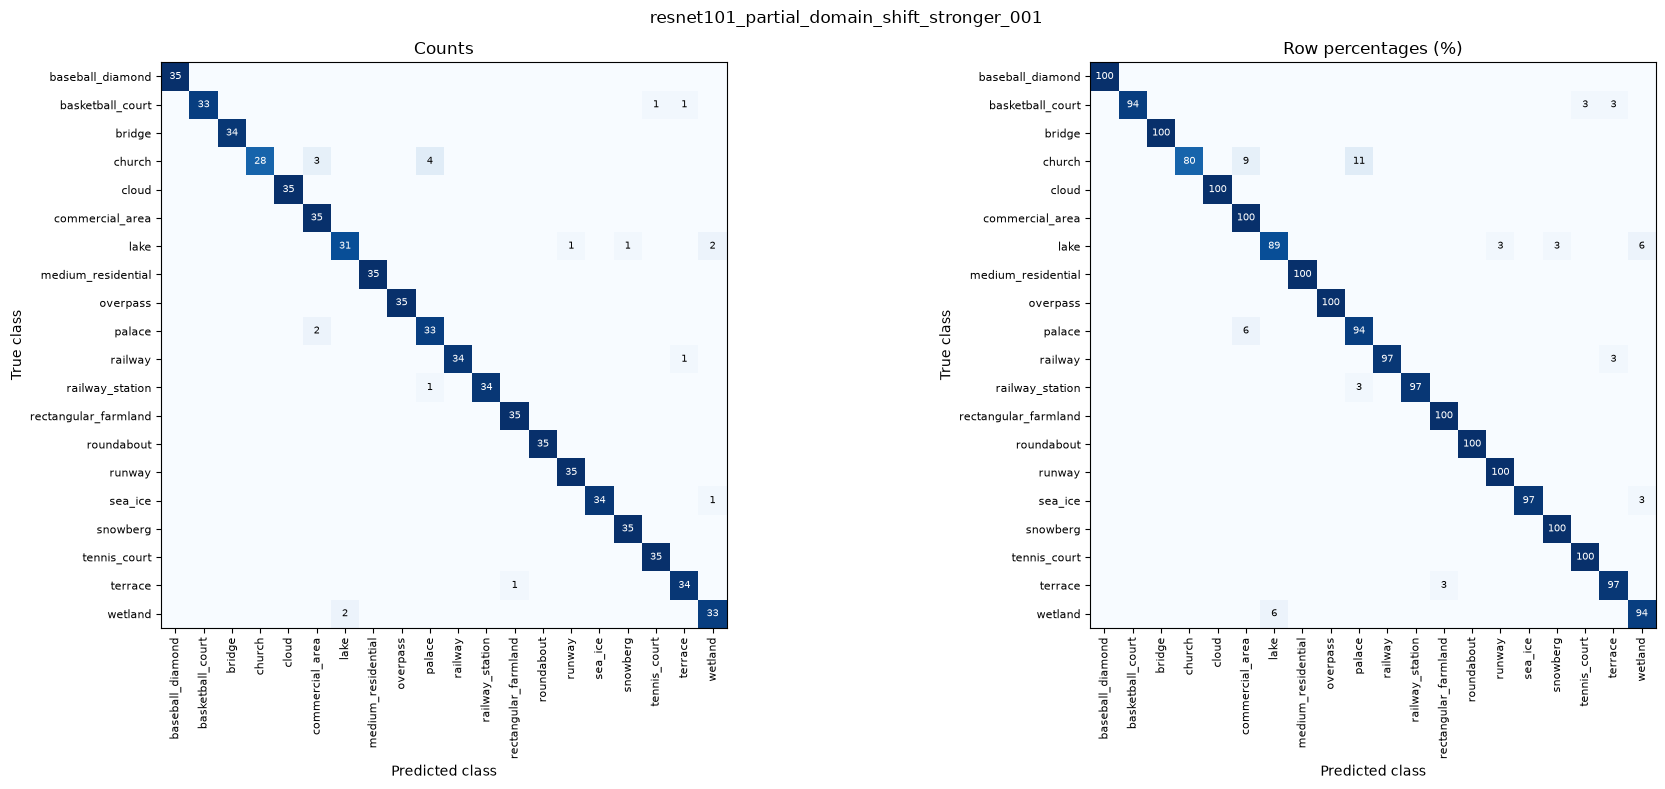

In [9]:
display(class_metrics(frame, PRIMARY, classes).round(2))
display(confusion_pairs(frame, PRIMARY, classes))
plot_confusion(frame, PRIMARY, classes)
plt.close("all")


## Все ошибочные объекты: картинка и top-k классов

Ошибки отсортированы по убыванию уверенности: сначала уверенные неправильные ответы. Оранжевый — неправильный top-1, зелёный — истинный класс, если он входит в top-k. Вероятность и место истинного класса указаны даже если его нет в top-k. Изображения исходные, без аугментаций.

Softmax — оценка модели, а не доказательство правильности. Для проверки калибровки потребовался бы отдельный анализ.


,id,true_class,predicted_class,correct,confidence,second_probability,margin,true_probability,true_rank
535,10647.jpg,church,palace,False,1.000000,1.341561e-07,1.000000,4.724612e-08,3
611,12301.jpg,lake,snowberg,False,1.000000,2.123259e-07,0.999999,2.097644e-07,3
214,4329.jpg,church,commercial_area,False,0.999981,1.783923e-05,0.999963,1.783923e-05,2
179,3617.jpg,church,palace,False,0.999585,4.125081e-04,0.999173,4.125081e-04,2
1,32.jpg,palace,commercial_area,False,0.997566,2.429519e-03,0.995137,2.429519e-03,2
92,1977.jpg,basketball_court,tennis_court,False,0.995733,3.683205e-03,0.992050,3.683205e-03,2
674,13473.jpg,lake,wetland,False,0.992995,6.888881e-03,0.986106,6.888881e-03,2
571,11562.jpg,palace,commercial_area,False,0.987267,1.206619e-02,0.975201,1.206619e-02,2
503,10127.jpg,terrace,rectangular_farmland,False,0.979869,2.012884e-02,0.959740,2.012884e-02,2
526,10472.jpg,church,palace,False,0.976124,2.377797e-02,0.952346,2.377797e-02,2


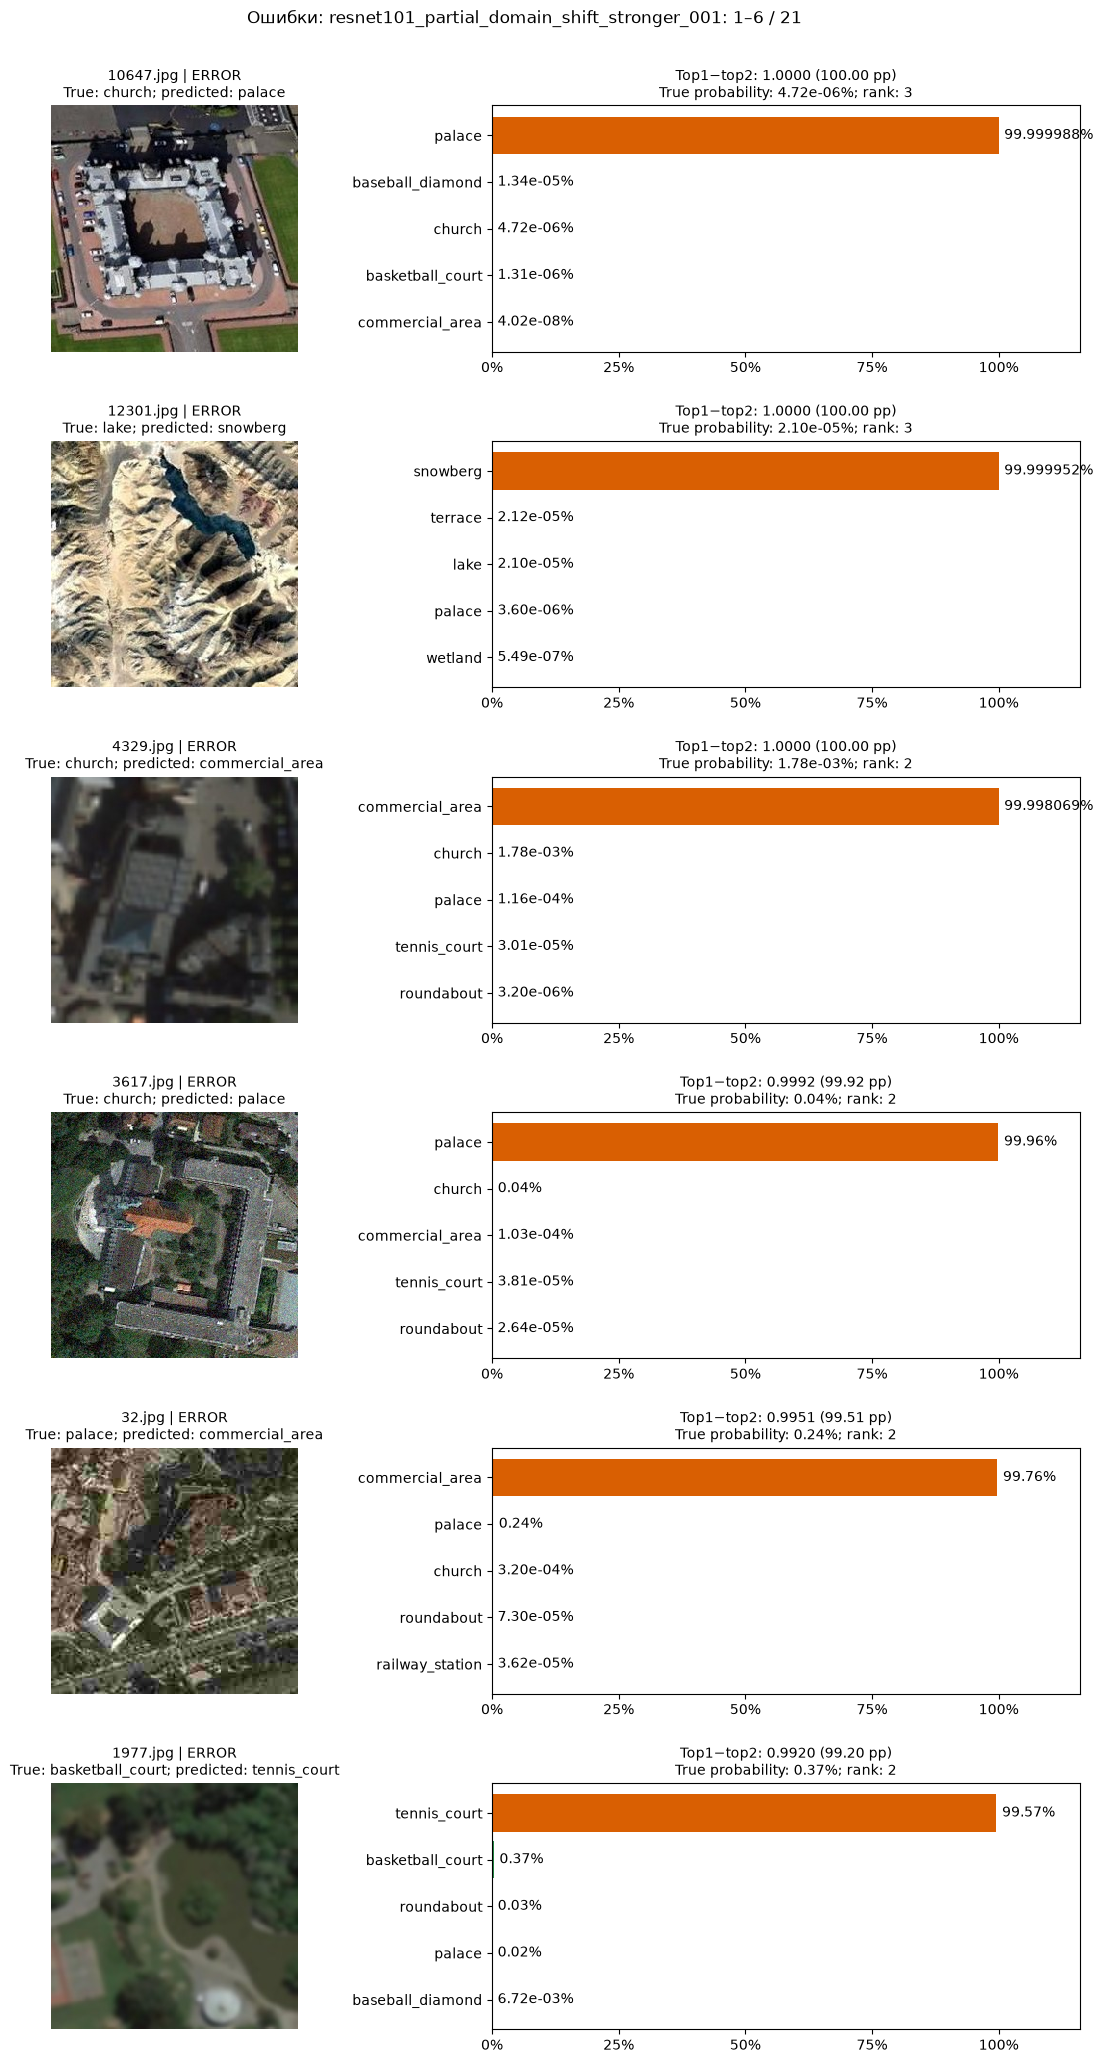

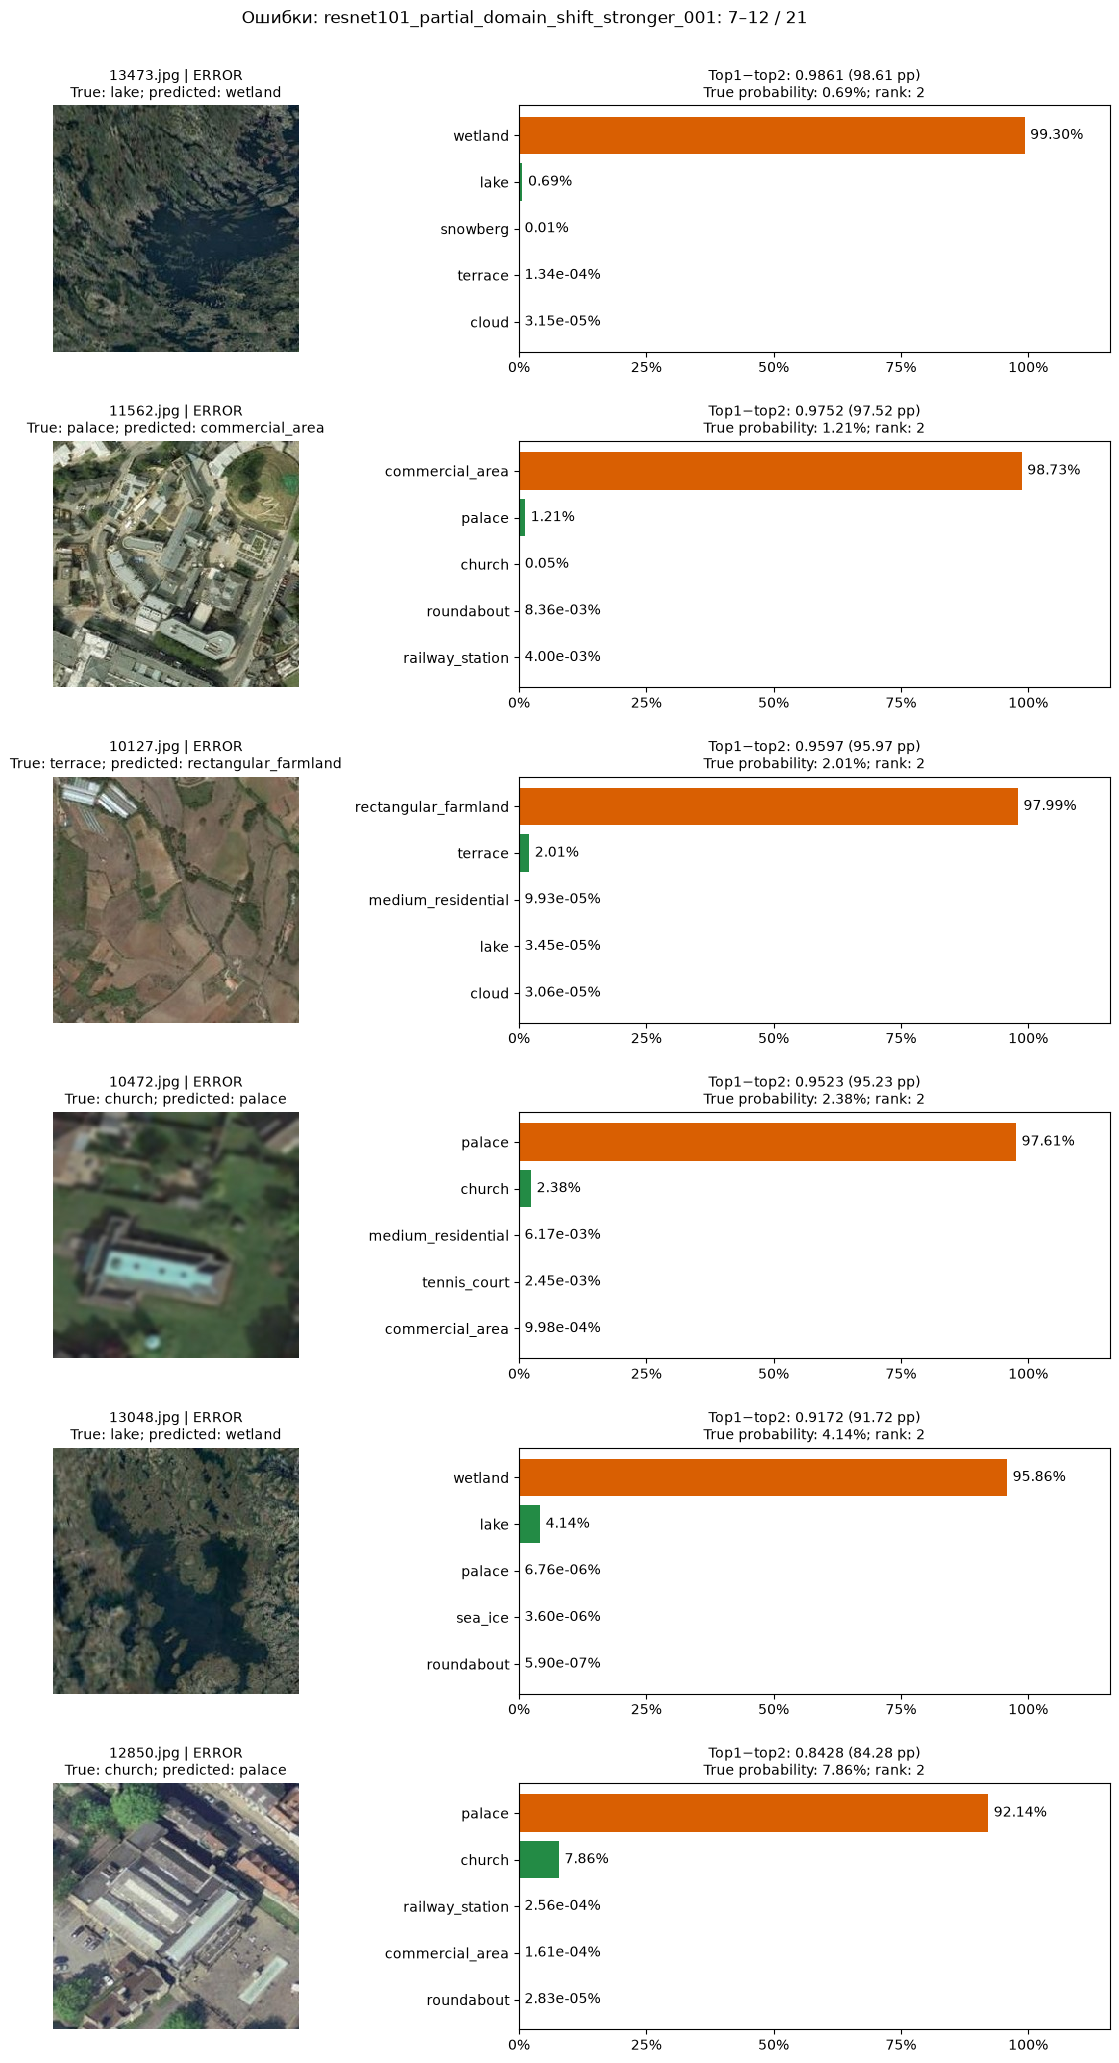

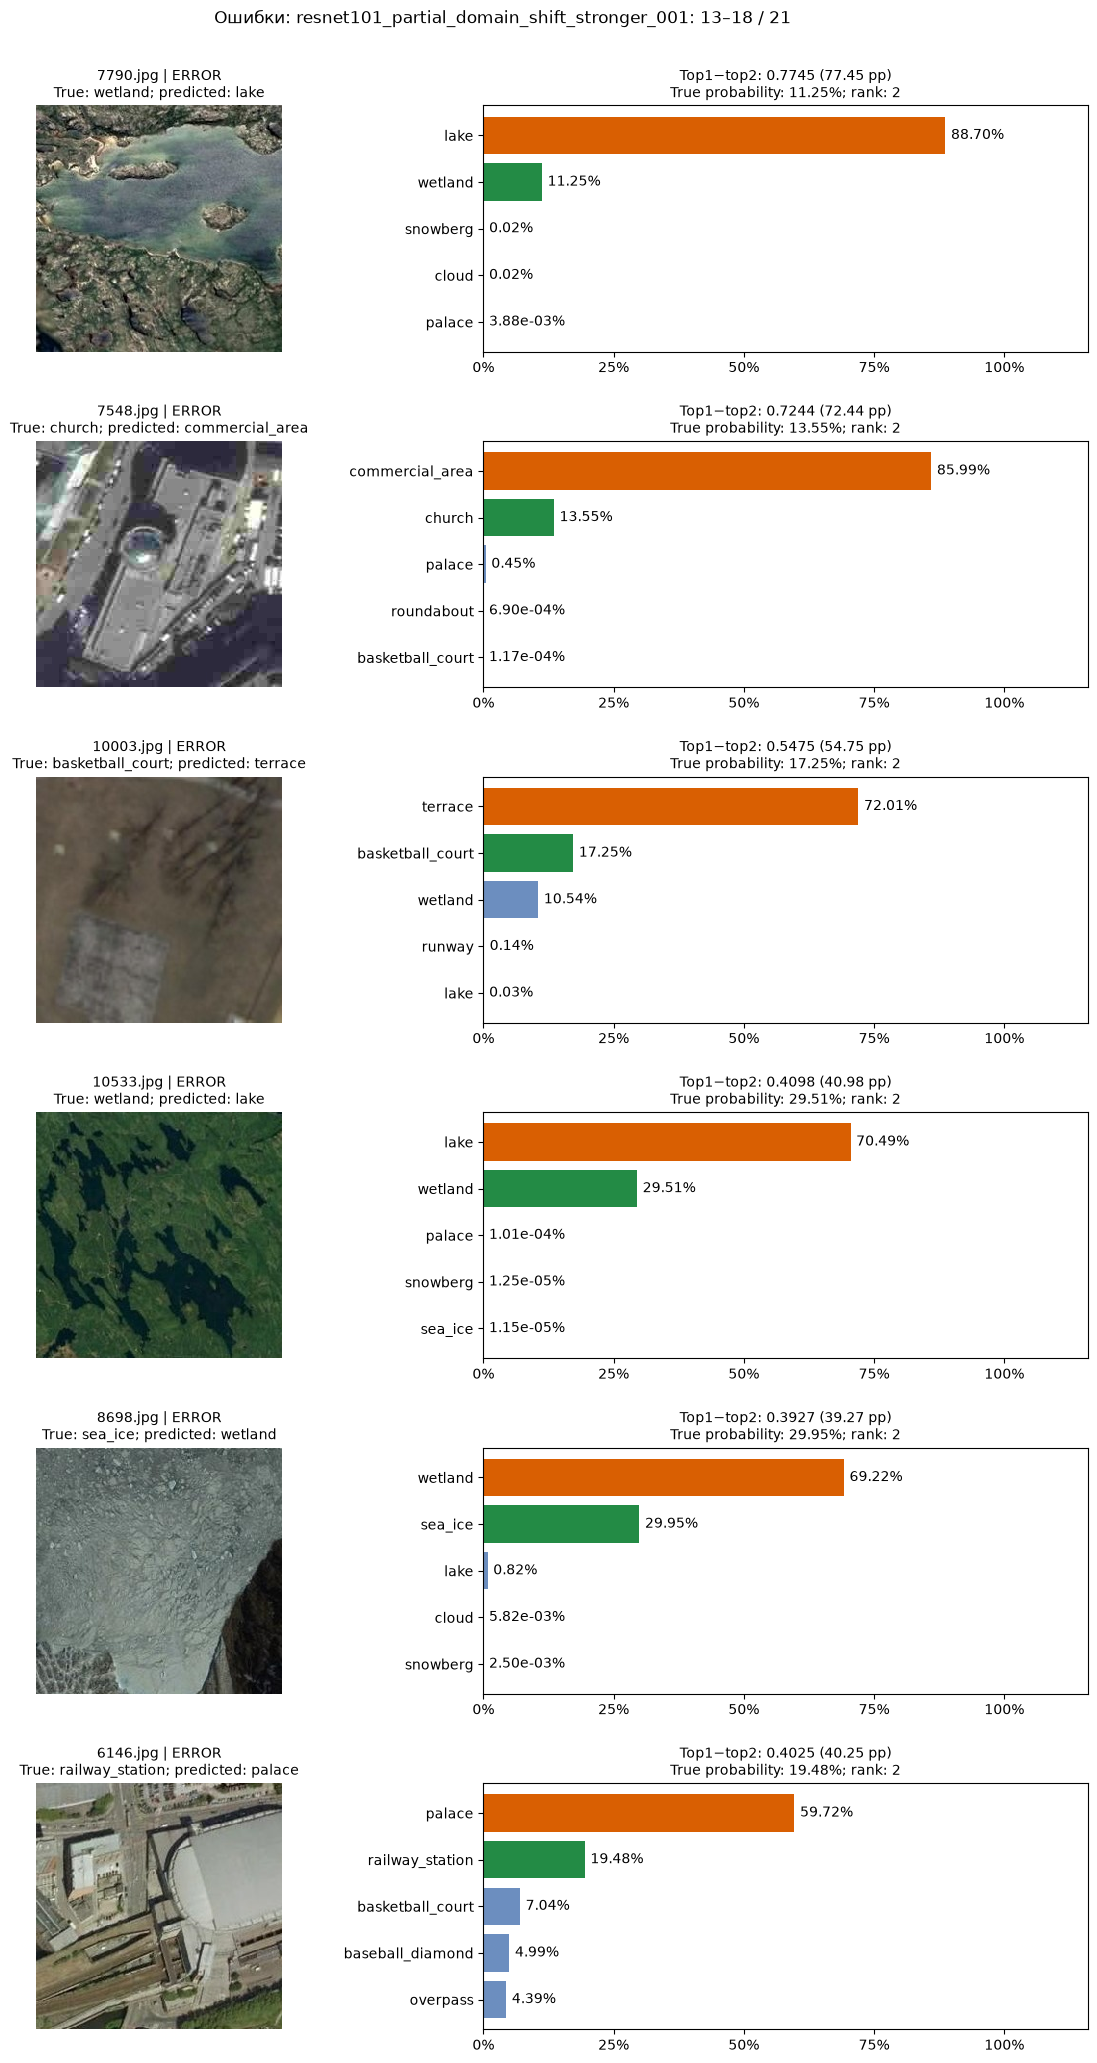

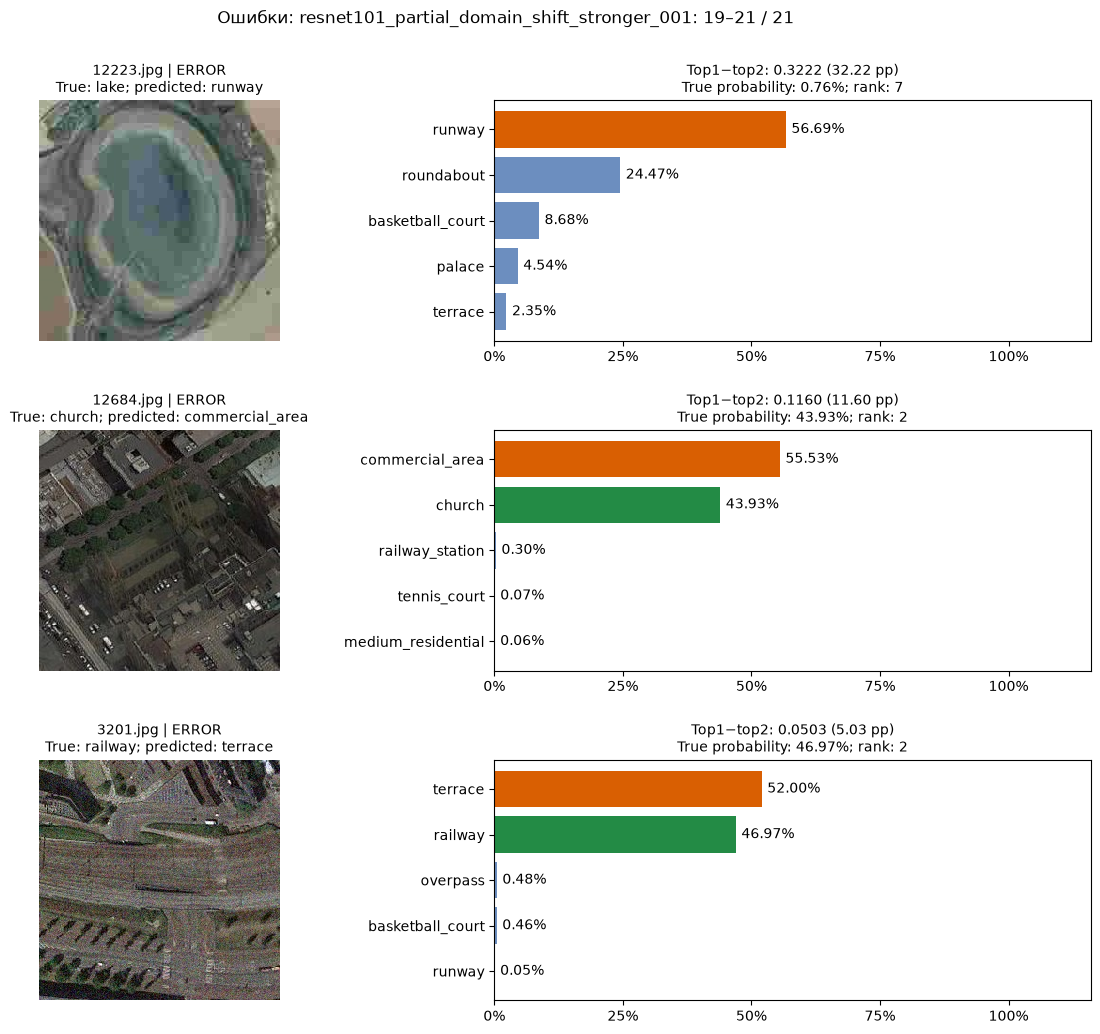

In [10]:
errors = probability_cases(probabilities, classes, selection="errors", top_k=TOP_K)
display(errors.drop(columns=["top_classes", "top_probabilities"]))
plot_probability_cases(errors, RAW_DIR / "val", f"Ошибки: {EXPERIMENT_ID}", page_size=PAGE_SIZE)
plt.close("all")


## Самые неоднозначные ответы: минимальный разрыв top-1/top-2

Берём UNCERTAIN_TOP_N объектов **из всей val**, включая правильные и ошибочные. Сортируем по p₁−p₂, а не по разметке или низкой p₁. Чем меньше разрыв, тем ближе два ведущих кандидата. Это относительный top-N: все эти объекты не обязательно имеют почти равные вероятности.


Показаны 30 объектов; среди них ошибок: 8


,id,true_class,predicted_class,correct,confidence,second_probability,margin,true_probability,true_rank
236,4761.jpg,tennis_court,tennis_court,True,0.363221,0.350202,0.013019,0.363221,1
160,3201.jpg,railway,terrace,False,0.519994,0.469652,0.050342,0.469652,2
148,2988.jpg,palace,palace,True,0.540401,0.442460,0.097940,0.540401,1
451,9099.jpg,commercial_area,commercial_area,True,0.481871,0.376202,0.105669,0.481871,1
631,12684.jpg,church,commercial_area,False,0.555328,0.439297,0.116031,0.439297,2
349,6989.jpg,commercial_area,commercial_area,True,0.532545,0.381257,0.151289,0.532545,1
610,12286.jpg,baseball_diamond,baseball_diamond,True,0.472792,0.299788,0.173003,0.472792,1
346,6931.jpg,basketball_court,basketball_court,True,0.555707,0.331523,0.224184,0.555707,1
352,7044.jpg,palace,palace,True,0.620193,0.379796,0.240397,0.620193,1
328,6615.jpg,medium_residential,medium_residential,True,0.627581,0.370486,0.257095,0.627581,1


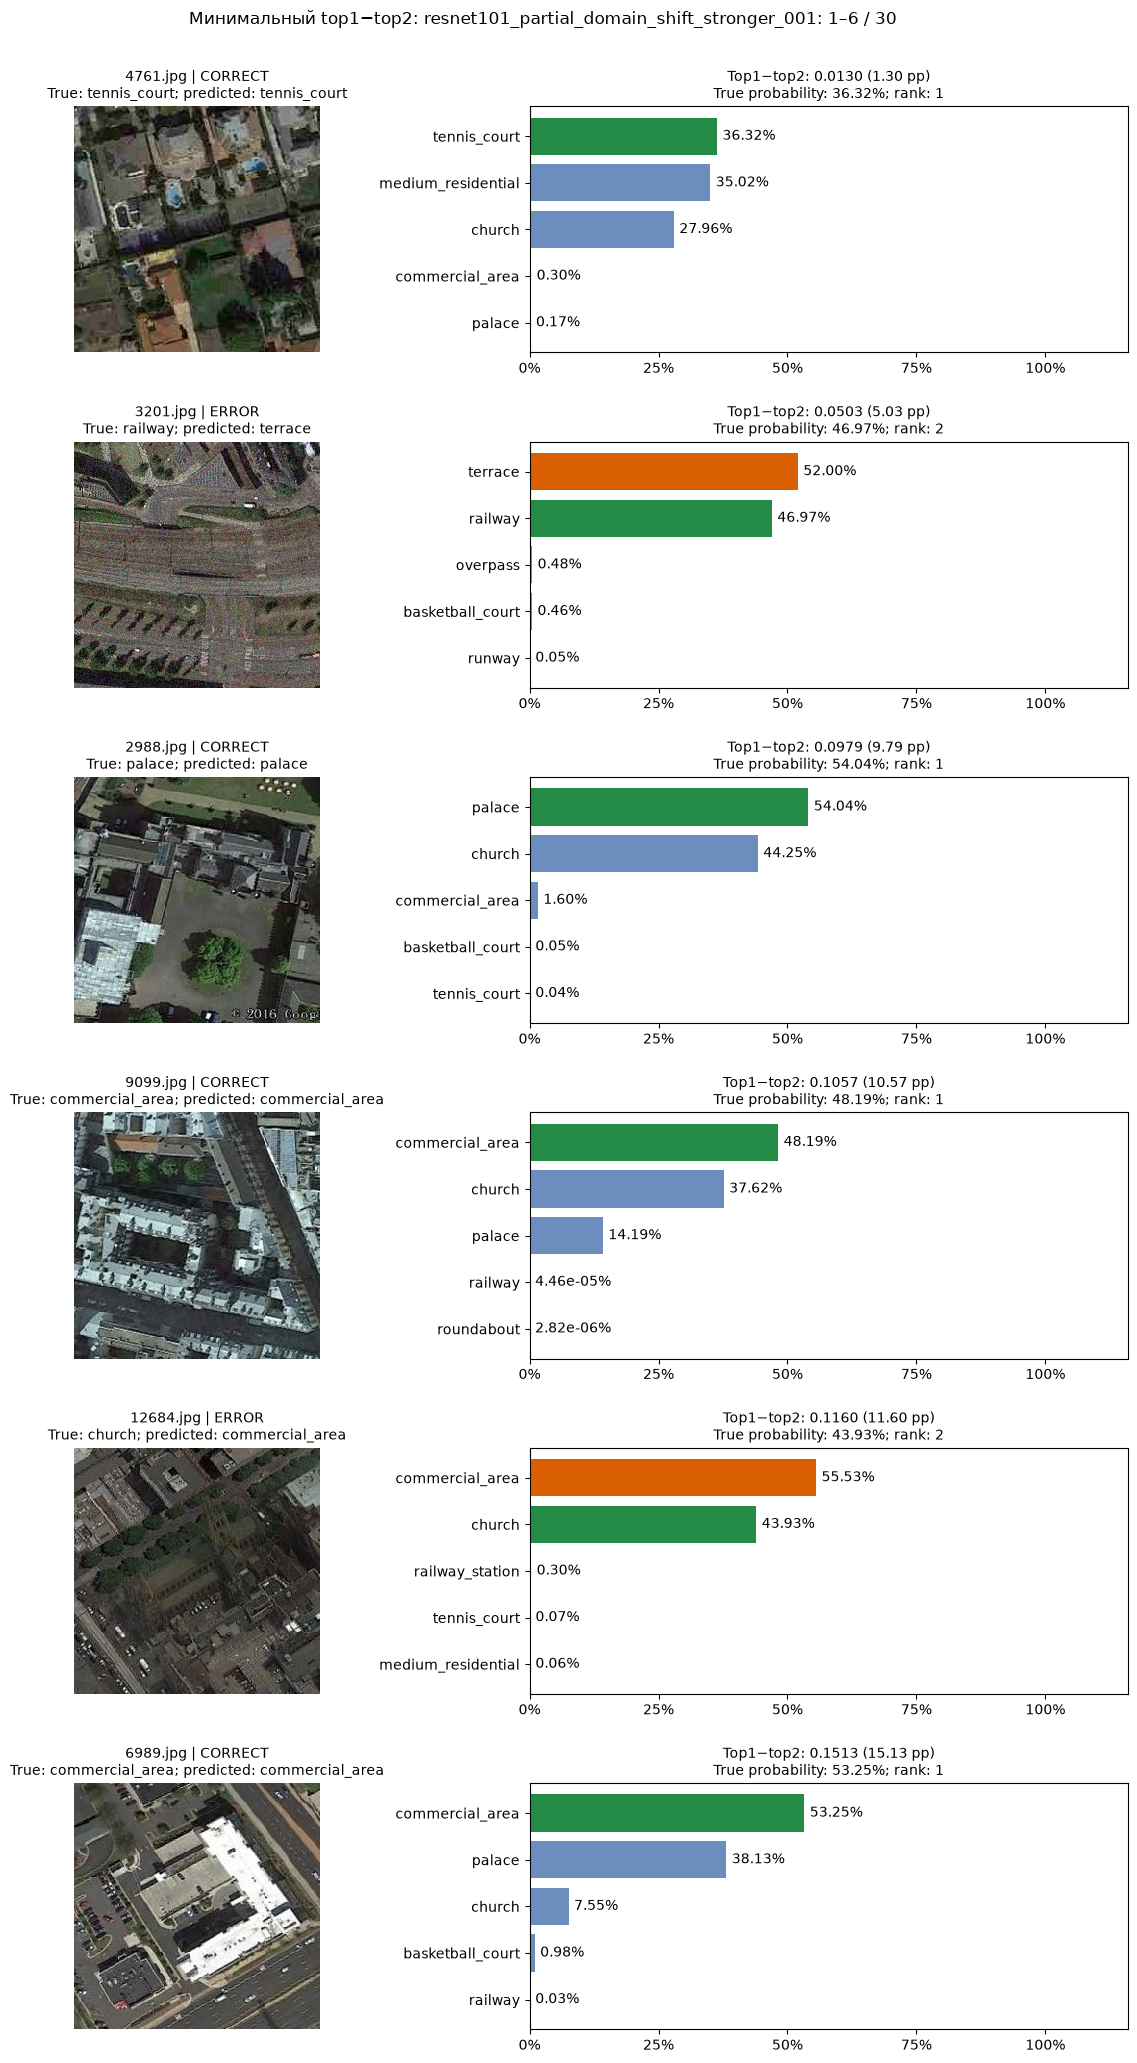

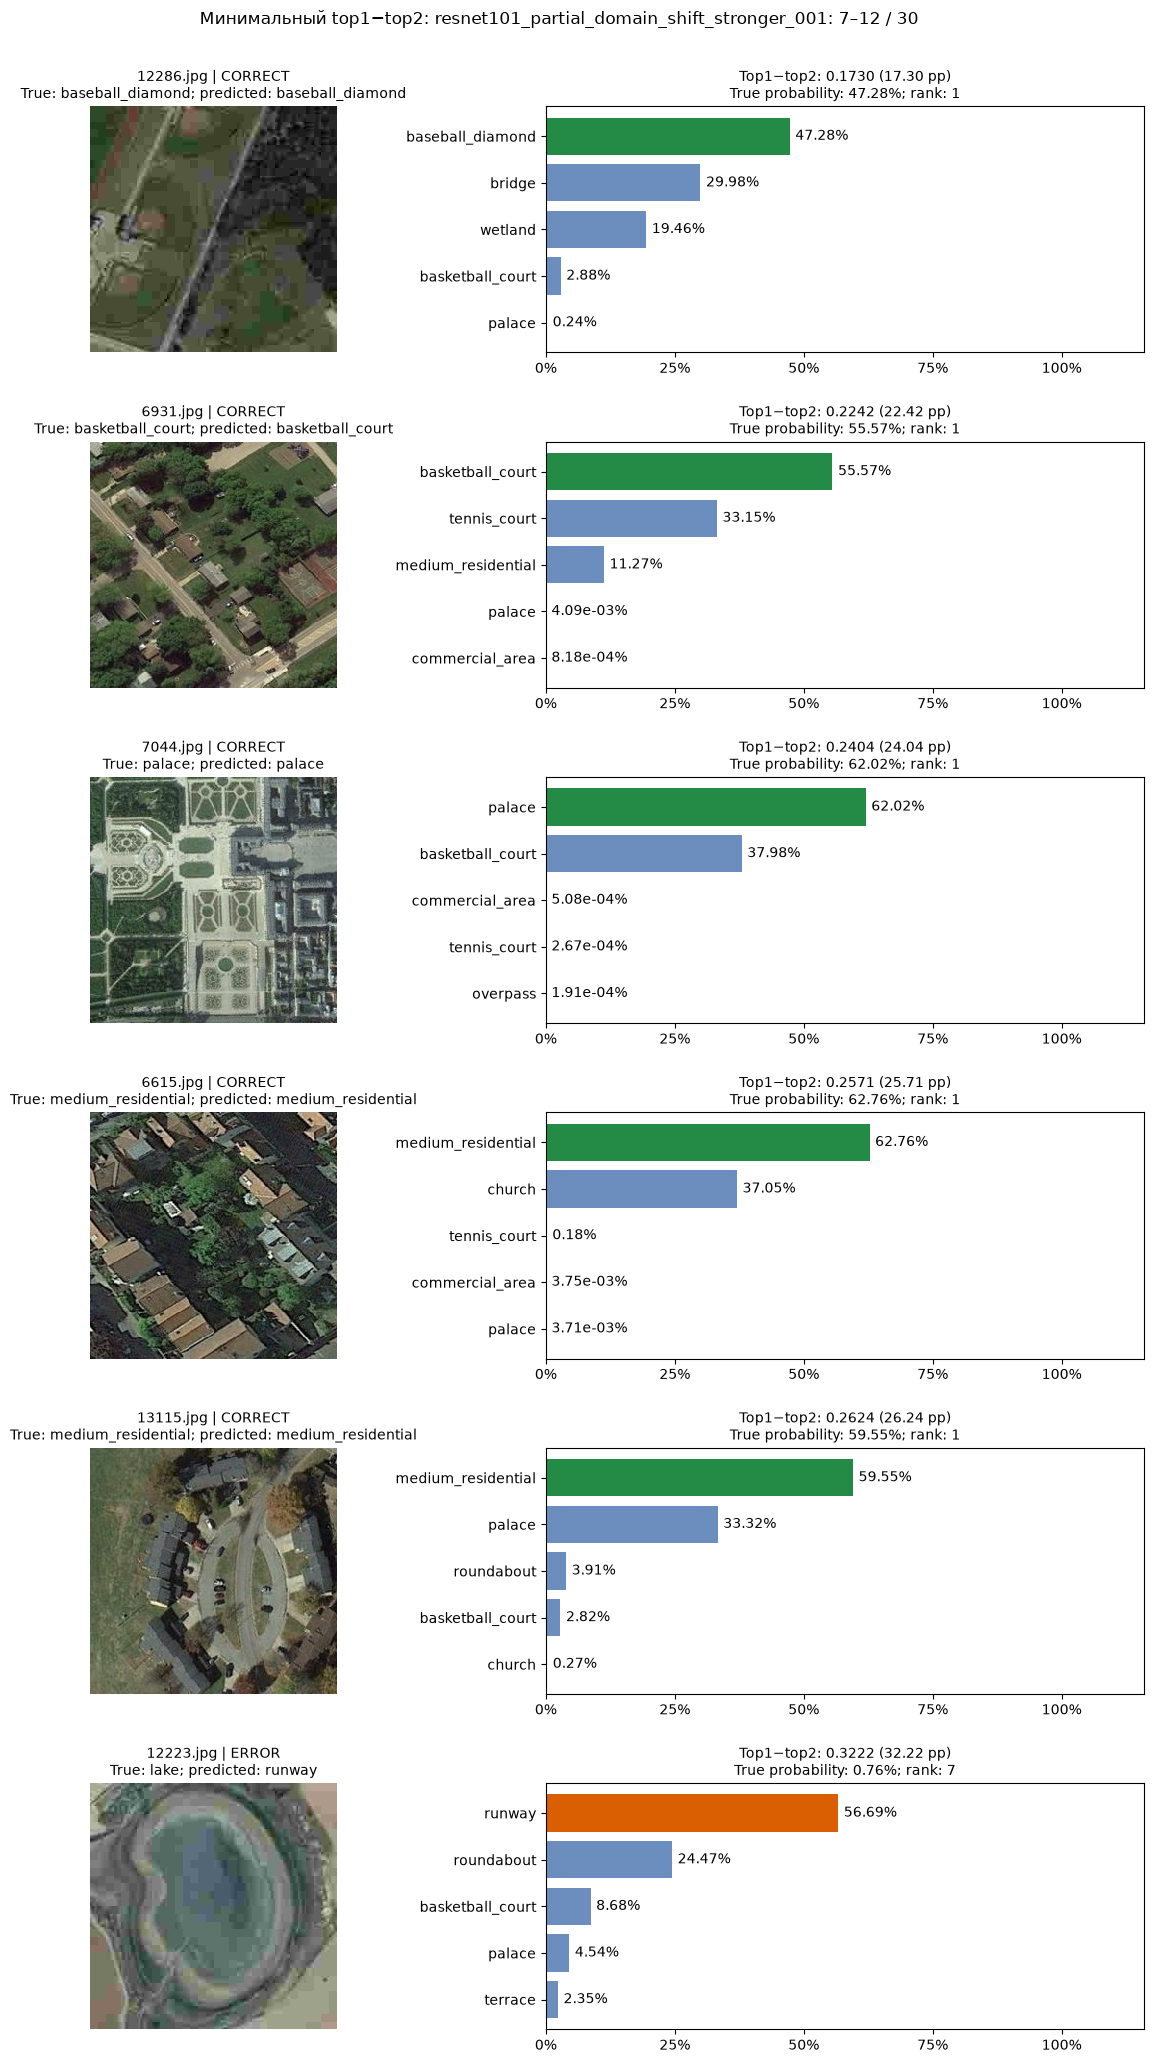

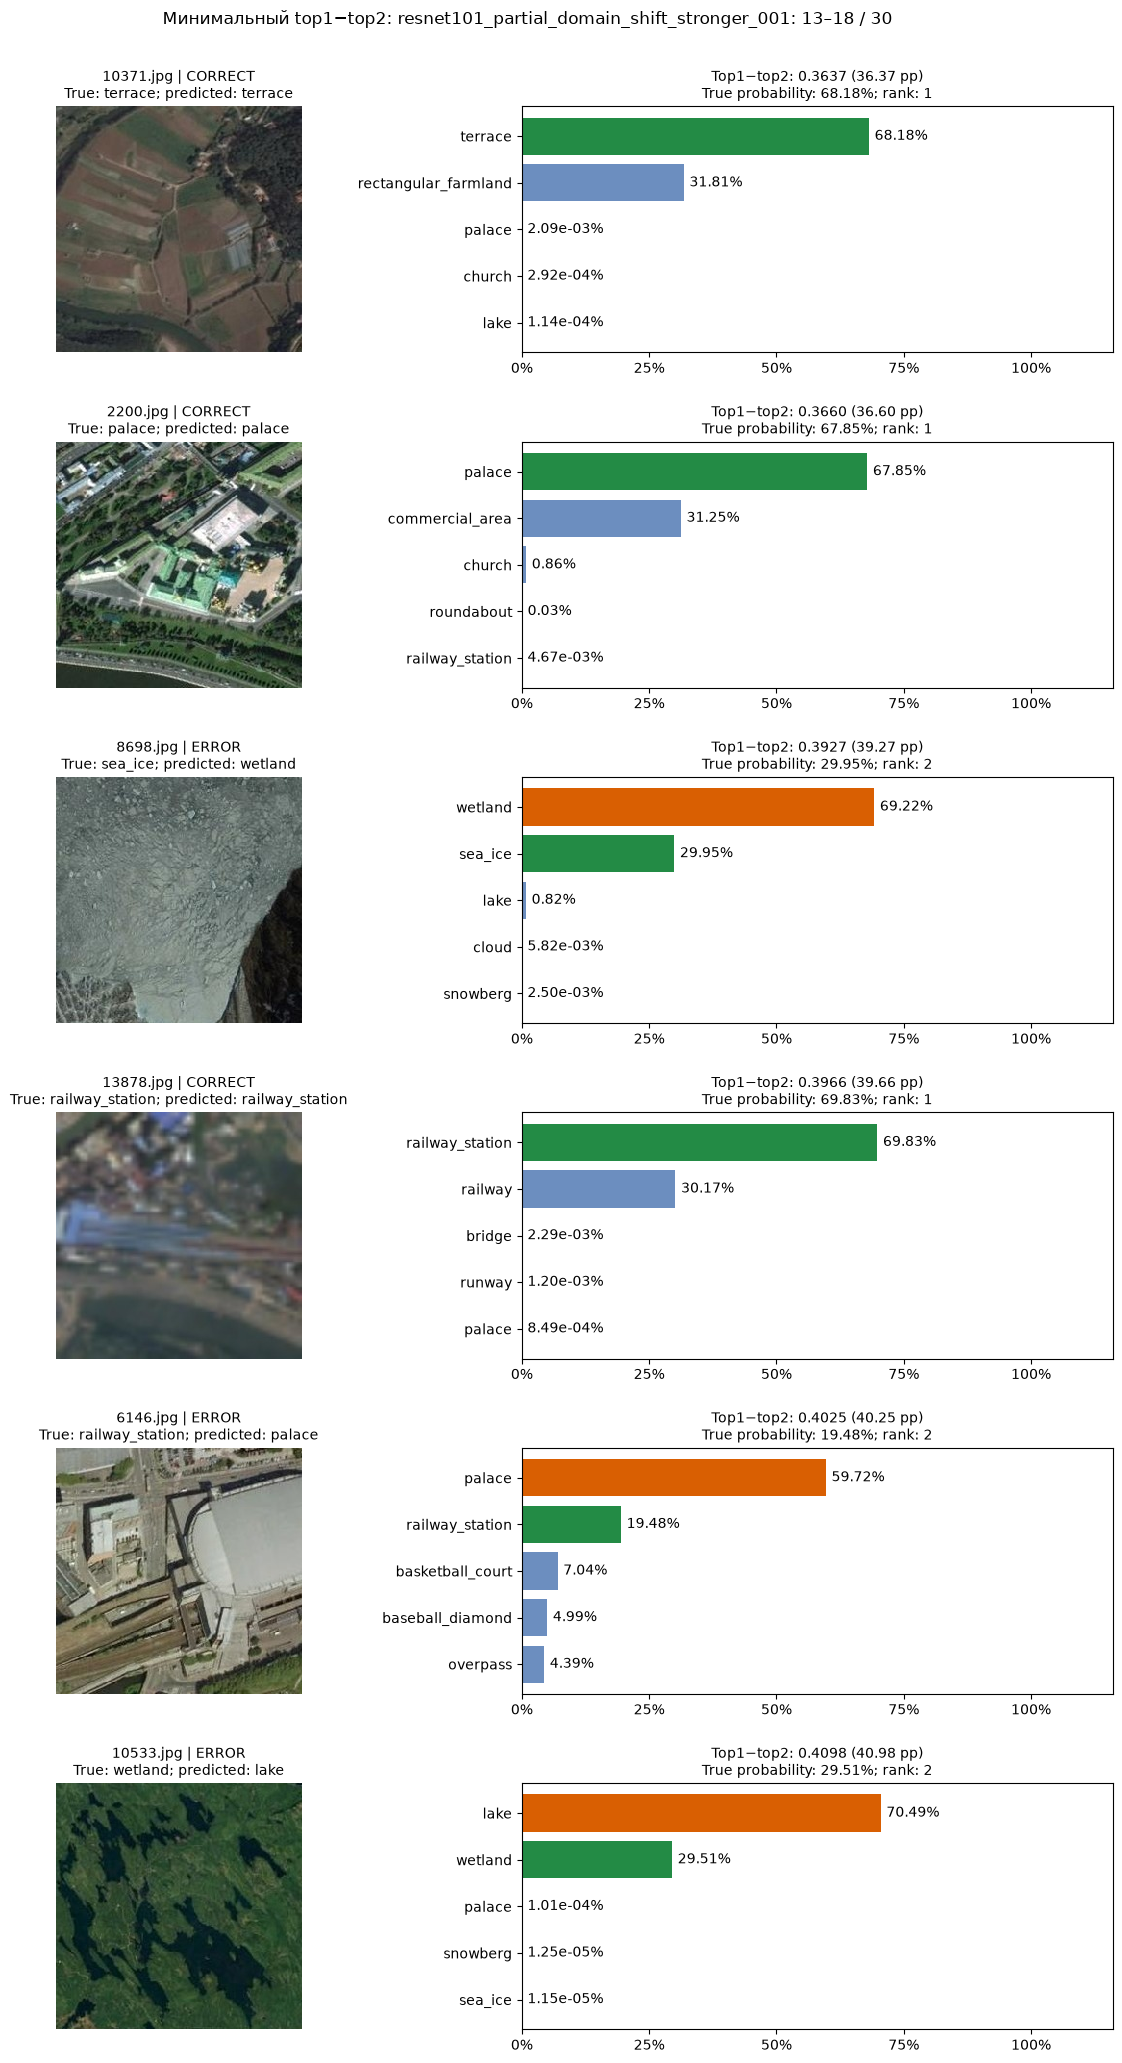

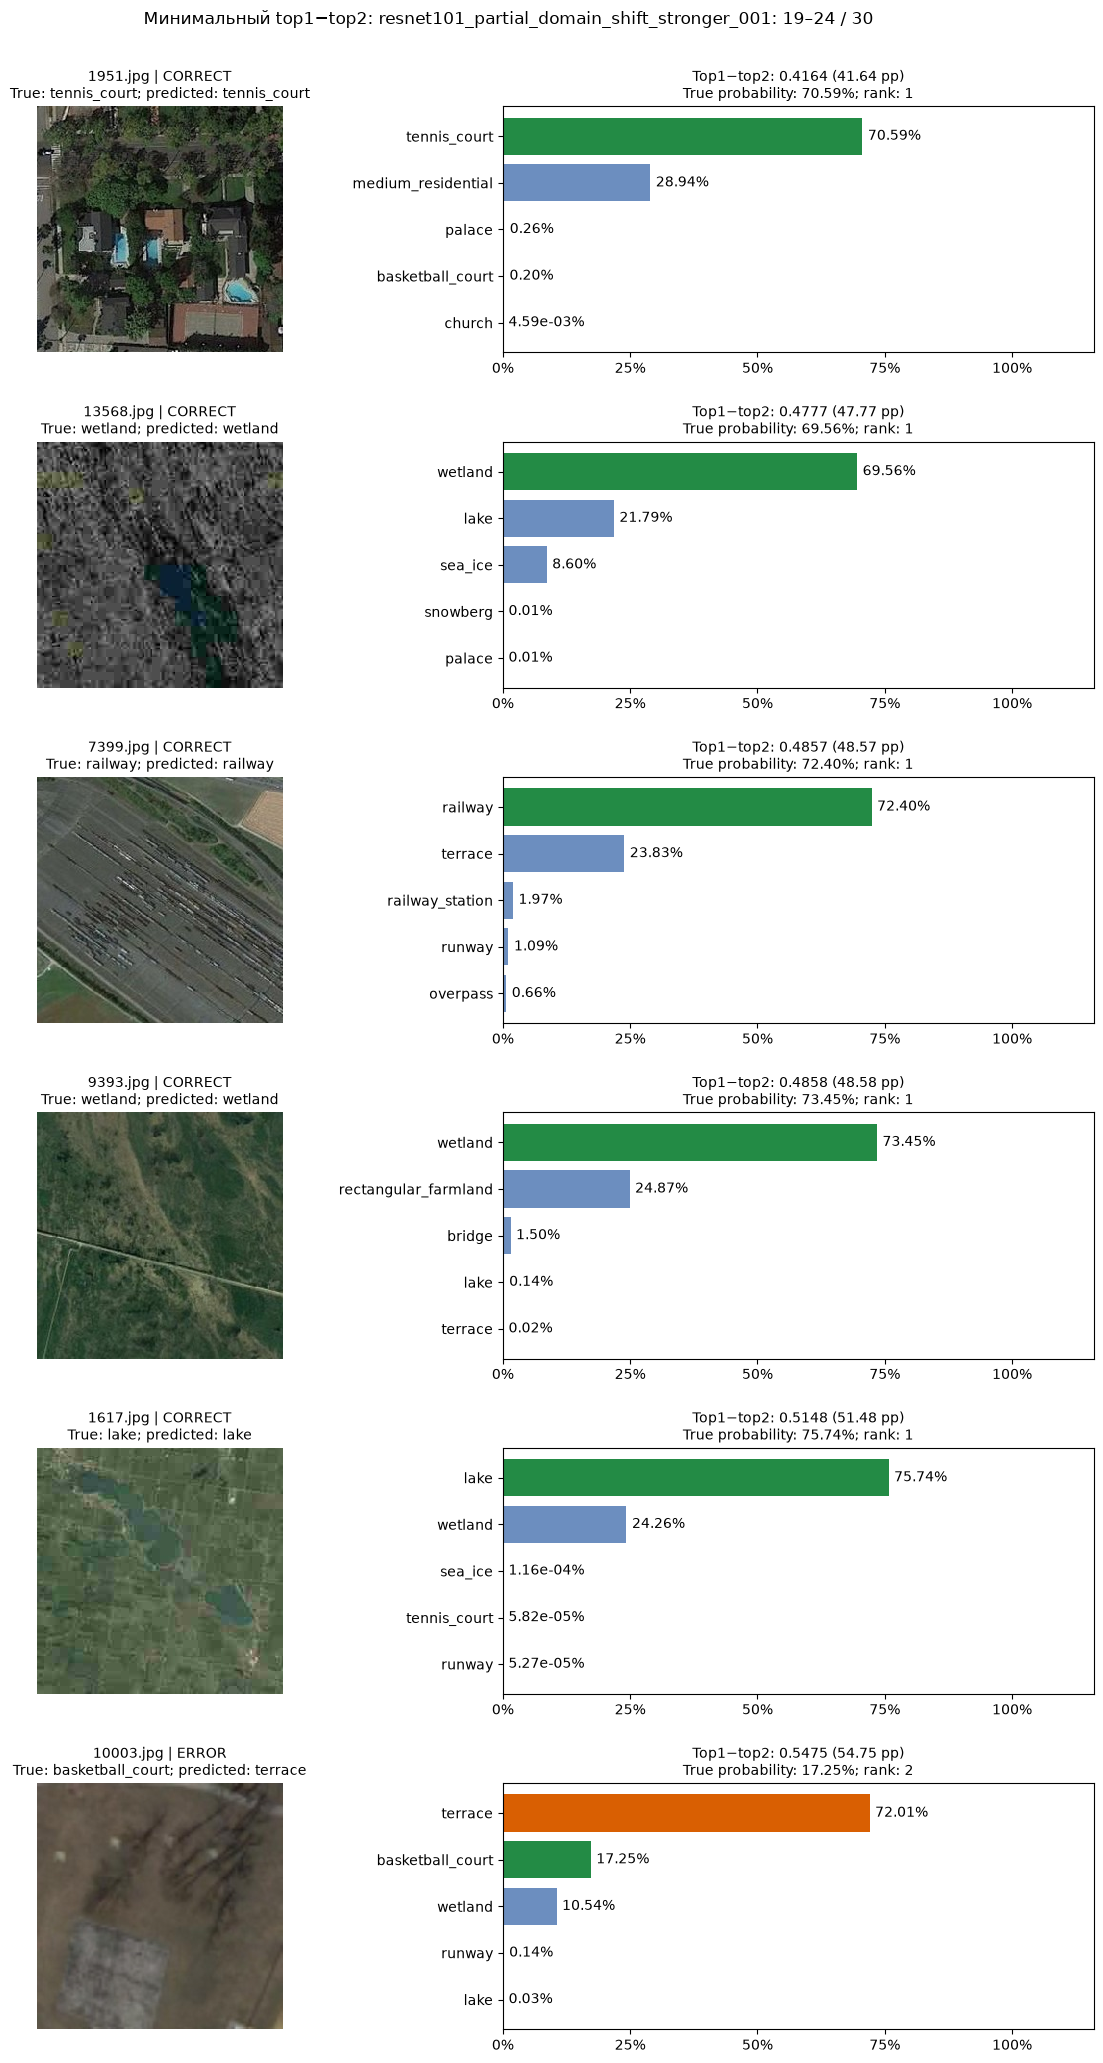

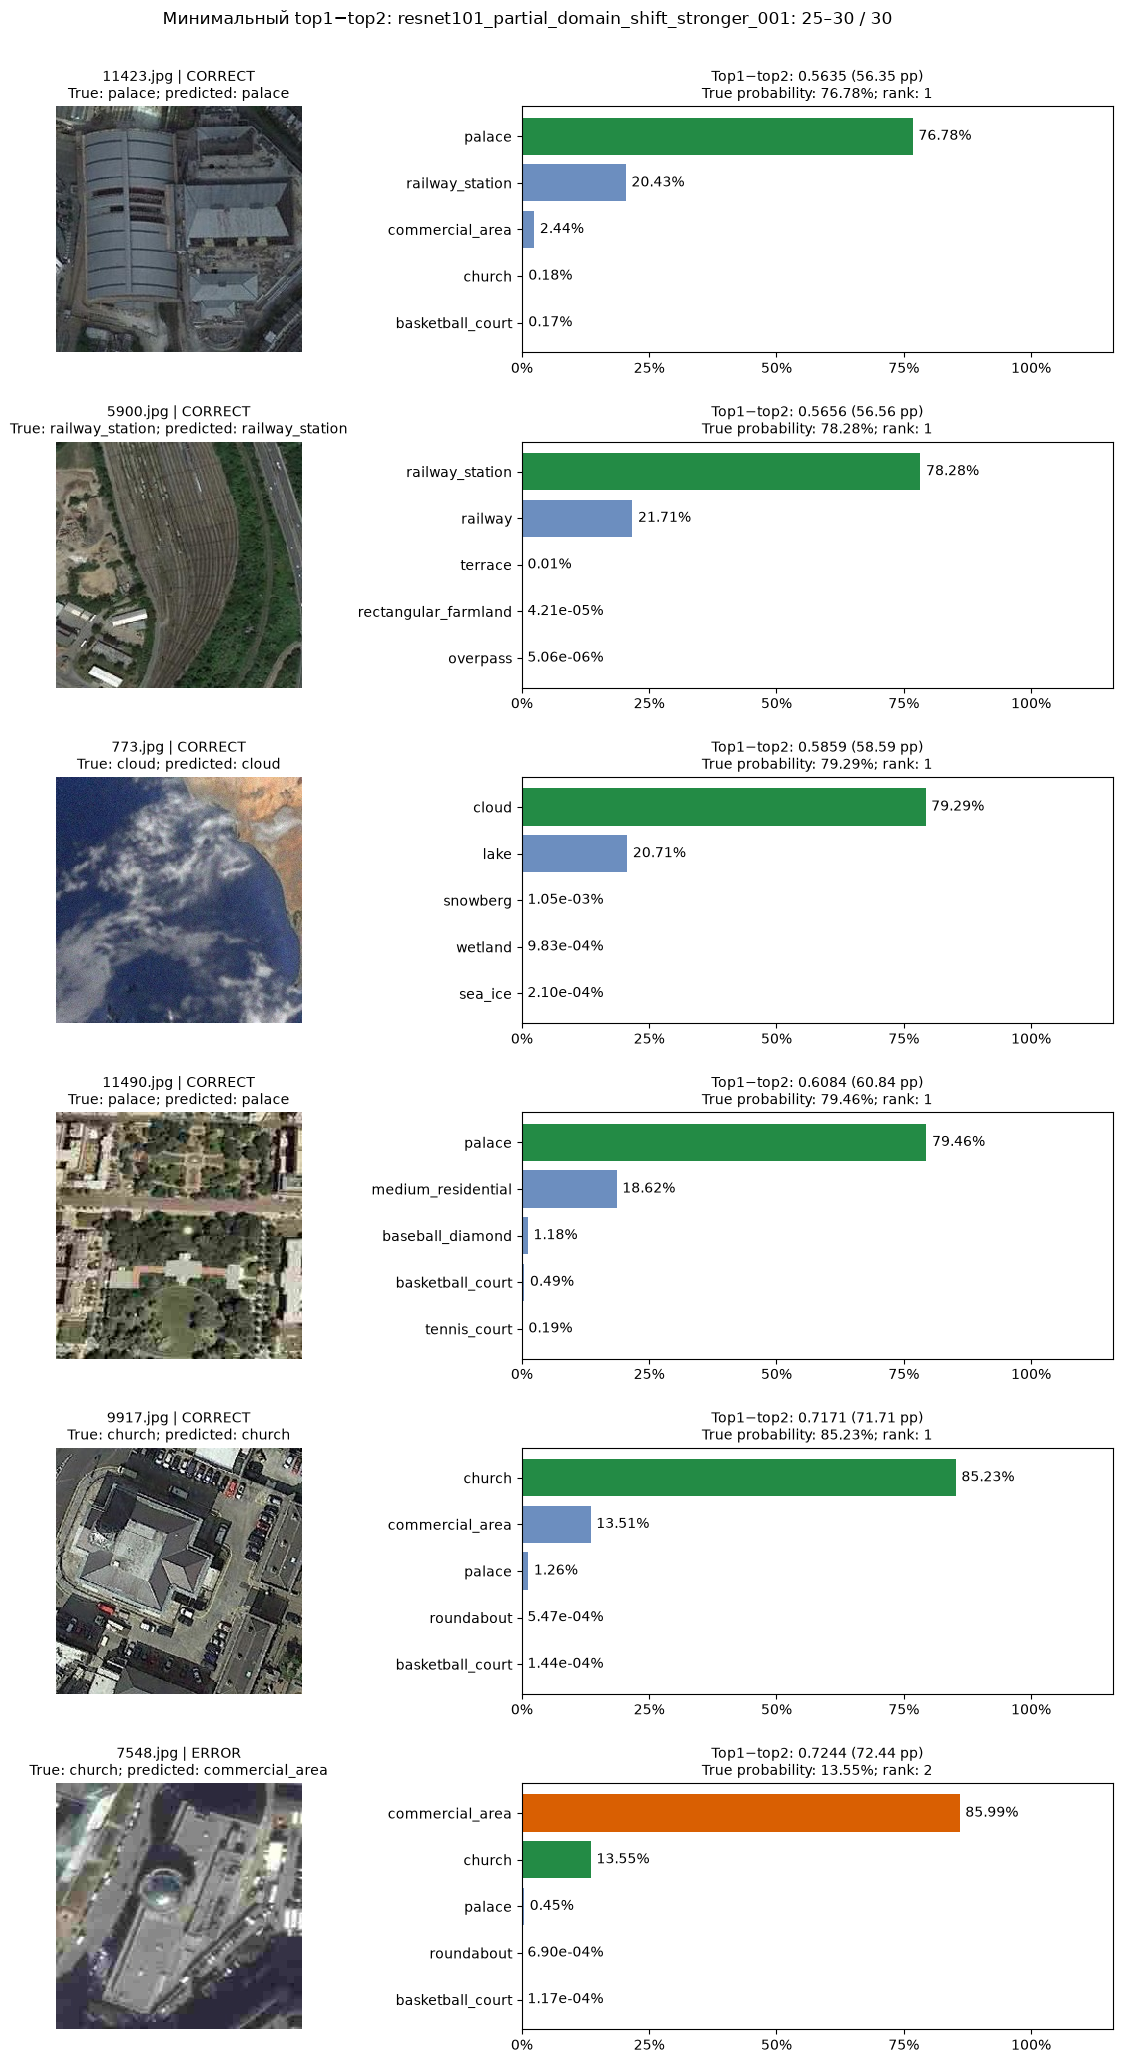

In [11]:
uncertain = probability_cases(probabilities, classes, selection="uncertain",
                              limit=UNCERTAIN_TOP_N, top_k=TOP_K)
print(f"Показаны {len(uncertain)} объектов; "
      f"среди них ошибок: {(~uncertain.correct).sum()}")
display(uncertain.drop(columns=["top_classes", "top_probabilities"]))
plot_probability_cases(uncertain, RAW_DIR / "val", f"Минимальный top1−top2: {EXPERIMENT_ID}", page_size=PAGE_SIZE)
plt.close("all")


## Необязательные дополнительные просмотры

Фильтр конкретной путаницы и случайные исходные train-примеры. Включайте при необходимости; по умолчанию дополнительные галереи выключены.


In [12]:
SHOW_EXTRA_GALLERIES = False
if SHOW_EXTRA_GALLERIES:
    show_errors(frame, PRIMARY, classes, RAW_DIR, true_class="church", predicted_class="palace")
    show_train_examples(RAW_DIR, classes, ["church", "palace", "commercial_area"], examples_per_class=3)
    plt.close("all")
